#**Decision Trees and Support Vector Machines**

###**Import Libraries**

In [18]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.preprocessing import StandardScaler
from sklearn.datasets import make_moons
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix
)

np.random.seed(42)

print("All libraries imported successfully.")


All libraries imported successfully.


###**Load the Banknote Authentication dataset**

In [19]:
file_path = "/content/data_banknote_authentication.txt"

column_names = [
    "variance",
    "skewness",
    "curtosis",
    "entropy",
    "class"
]

df = pd.read_csv(
    file_path,
    header=None,
    names=column_names
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Shape: (1372, 5)


,variance,skewness,curtosis,entropy,class
0,3.62160,8.6661,-2.8073,-0.44699,0
1,4.54590,8.1674,-2.4586,-1.46210,0
2,3.86600,-2.6383,1.9242,0.10645,0
3,3.45660,9.5228,-4.0112,-3.59440,0
4,0.32924,-4.4552,4.5718,-0.98880,0


###**Visualize the two features we'll use for decision boundaries**

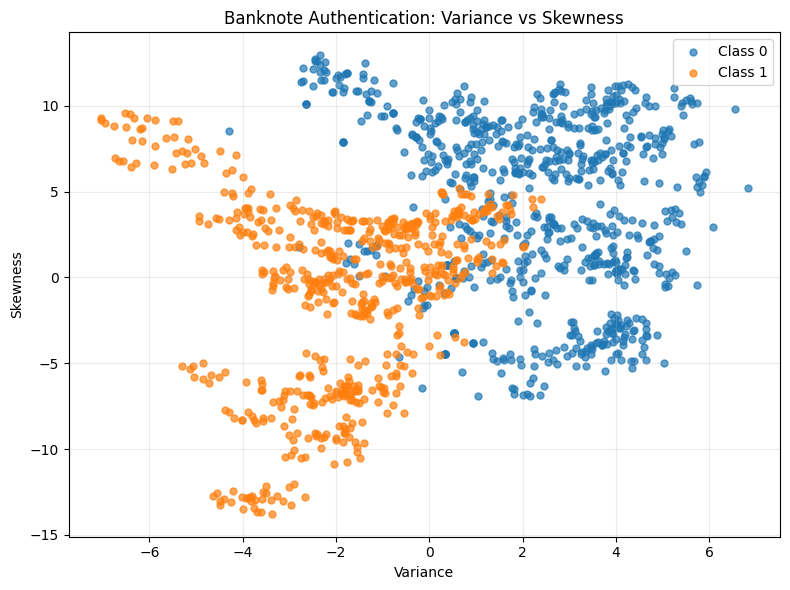

In [20]:
plt.figure(figsize=(8, 6))

for label in sorted(df["class"].unique()):
    subset = df[df["class"] == label]

    plt.scatter(
        subset["variance"],
        subset["skewness"],
        label=f"Class {label}",
        alpha=0.7,
        s=25
    )

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Banknote Authentication: Variance vs Skewness")
plt.legend()
plt.grid(alpha=0.25)
plt.tight_layout()
plt.show()

###**Define features and target**

In [21]:
X = df[["variance", "skewness", "curtosis", "entropy"]].to_numpy()
y = df["class"].to_numpy()

# Two features for decision-boundary plots
X_2d = df[["variance", "skewness"]].to_numpy()

print("Full feature matrix shape:", X.shape)
print("Target shape:", y.shape)
print("Two-feature matrix shape:", X_2d.shape)

Full feature matrix shape: (1372, 4)
Target shape: (1372,)
Two-feature matrix shape: (1372, 2)


###**Create a consistent train-test split**

In [22]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

# Split the two-feature data using the same indices
indices = np.arange(len(y))

train_indices, test_indices = train_test_split(
    indices,
    test_size=0.20,
    random_state=42,
    stratify=y
)

X_train_2d = X_2d[train_indices]
X_test_2d = X_2d[test_indices]

print("Four-feature training set:", X_train.shape)
print("Four-feature testing set:", X_test.shape)
print("Two-feature training set:", X_train_2d.shape)
print("Two-feature testing set:", X_test_2d.shape)
print("Training class counts:", np.bincount(y_train))
print("Testing class counts:", np.bincount(y_test))

Four-feature training set: (1097, 4)
Four-feature testing set: (275, 4)
Two-feature training set: (1097, 2)
Two-feature testing set: (275, 2)
Training class counts: [609 488]
Testing class counts: [153 122]


##**Part A - Decision Tree from Scratch**

###**Gini Impurity and Entropy**

In [23]:
def gini_impurity(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return 1.0 - np.sum(probabilities ** 2)


def entropy(y):
    if len(y) == 0:
        return 0.0

    _, counts = np.unique(y, return_counts=True)
    probabilities = counts / len(y)

    return -np.sum(
        probabilities * np.log2(probabilities)
    )


# Verify both functions
test_labels = np.array([0, 0, 1, 1])

print("Gini for balanced labels:", gini_impurity(test_labels))
print("Entropy for balanced labels:", entropy(test_labels))

pure_labels = np.array([1, 1, 1, 1])

print("Gini for pure labels:", gini_impurity(pure_labels))
print("Entropy for pure labels:", entropy(pure_labels))


Gini for balanced labels: 0.5
Entropy for balanced labels: 1.0
Gini for pure labels: 0.0
Entropy for pure labels: -0.0


###**Feature and Threshold**

In [25]:
def best_split(X, y, criterion="gini"):
    n_samples, n_features = X.shape

    if n_samples < 2:
        return None, None, None

    if criterion == "gini":
        impurity_function = gini_impurity
    elif criterion == "entropy":
        impurity_function = entropy
    else:
        raise ValueError("Criterion must be 'gini' or 'entropy'.")

    parent_impurity = impurity_function(y)

    best_gain = 0.0
    best_feature = None
    best_threshold = None

    for feature_index in range(n_features):
        values = np.unique(X[:, feature_index])

        # Midpoints between consecutive unique values
        thresholds = (values[:-1] + values[1:]) / 2.0

        for threshold in thresholds:
            left_mask = X[:, feature_index] <= threshold
            right_mask = ~left_mask

            y_left = y[left_mask]
            y_right = y[right_mask]

            if len(y_left) == 0 or len(y_right) == 0:
                continue

            weighted_impurity = (
                len(y_left) / n_samples * impurity_function(y_left)
                + len(y_right) / n_samples * impurity_function(y_right)
            )

            gain = parent_impurity - weighted_impurity

            if gain > best_gain:
                best_gain = gain
                best_feature = feature_index
                best_threshold = threshold

    return best_feature, best_threshold, best_gain


###**Test the split function**

In [26]:
X_small = np.array([
    [1.0, 10.0],
    [2.0, 10.0],
    [3.0, 20.0],
    [4.0, 20.0]
])

y_small = np.array([0, 0, 1, 1])

for criterion in ["gini", "entropy"]:
    feature, threshold, gain = best_split(
        X_small,
        y_small,
        criterion=criterion
    )

    print(f"\nCriterion: {criterion}")
    print("Best feature index:", feature)
    print("Best threshold:", threshold)
    print("Information gain:", gain)



Criterion: gini
Best feature index: 0
Best threshold: 2.5
Information gain: 0.5

Criterion: entropy
Best feature index: 0
Best threshold: 2.5
Information gain: 1.0


###**Implement the manual Decision Tree**

###**Recursive Decision Tree Construction**

In [27]:
def build_tree(
    X,
    y,
    criterion="gini",
    max_depth=None,
    min_samples_split=2,
    depth=0
):
    # Majority class at this node
    classes, counts = np.unique(y, return_counts=True)
    majority_class = classes[np.argmax(counts)]

    node = {
        "prediction": int(majority_class),
        "samples": len(y),
        "depth": depth
    }

    # Stop if the node is pure
    if len(classes) == 1:
        return node

    # Stop if maximum depth is reached
    if max_depth is not None and depth >= max_depth:
        return node

    # Stop if there are too few samples
    if len(y) < min_samples_split:
        return node

    feature, threshold, gain = best_split(X, y, criterion)

    # Stop if no useful split exists
    if feature is None or gain <= 0:
        return node

    left_mask = X[:, feature] <= threshold
    right_mask = ~left_mask

    node["feature"] = feature
    node["threshold"] = float(threshold)
    node["gain"] = float(gain)

    node["left"] = build_tree(
        X[left_mask],
        y[left_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    node["right"] = build_tree(
        X[right_mask],
        y[right_mask],
        criterion,
        max_depth,
        min_samples_split,
        depth + 1
    )

    return node


###**Implement Prediction**

In [28]:
def predict_one(node, sample):
    # Leaf node
    if "feature" not in node:
        return node["prediction"]

    feature = node["feature"]
    threshold = node["threshold"]

    if sample[feature] <= threshold:
        return predict_one(node["left"], sample)

    return predict_one(node["right"], sample)


def predict_tree(tree, X):
    return np.array([
        predict_one(tree, sample)
        for sample in X
    ])


###**Train and test the manual tree**

In [30]:
manual_tree = build_tree(
    X_train_2d,
    y_train,
    criterion="gini",
    max_depth=5,
    min_samples_split=2
)

manual_predictions = predict_tree(manual_tree, X_test_2d)

print("Manual Decision Tree")
print("Test accuracy:", accuracy_score(y_test, manual_predictions))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, manual_predictions))


Manual Decision Tree
Test accuracy: 0.9309090909090909

Confusion matrix:
[[137  16]
 [  3 119]]


###**Manual Decision Tree**

In [31]:
feature_names_2d = ["variance", "skewness"]


def print_tree(node, feature_names, indent=""):
    if "feature" not in node:
        print(
            indent
            + f"Predict class {node['prediction']} "
            + f"(samples={node['samples']})"
        )
        return

    feature = node["feature"]
    threshold = node["threshold"]

    print(
        indent
        + f"IF {feature_names[feature]} <= {threshold:.4f}"
    )

    print_tree(node["left"], feature_names, indent + "  ")

    print(indent + "ELSE")

    print_tree(node["right"], feature_names, indent + "  ")


print_tree(manual_tree, feature_names_2d)


IF variance <= 0.7651
  IF skewness <= 5.1608
    IF variance <= 0.3202
      IF variance <= -0.4586
        IF skewness <= 0.0548
          Predict class 1 (samples=208)
        ELSE
          Predict class 1 (samples=138)
      ELSE
        IF skewness <= -0.1666
          Predict class 1 (samples=27)
        ELSE
          Predict class 1 (samples=40)
    ELSE
      IF skewness <= 3.2197
        IF variance <= 0.7406
          Predict class 0 (samples=34)
        ELSE
          Predict class 1 (samples=5)
      ELSE
        Predict class 1 (samples=12)
  ELSE
    IF variance <= -3.4311
      IF variance <= -4.3819
        Predict class 1 (samples=29)
      ELSE
        IF variance <= -4.2554
          Predict class 0 (samples=1)
        ELSE
          Predict class 1 (samples=2)
    ELSE
      IF skewness <= 5.3646
        IF variance <= 0.6458
          Predict class 1 (samples=1)
        ELSE
          Predict class 0 (samples=1)
      ELSE
        Predict class 0 (samples=95)
ELS

###**Visualize the Manual Decision Tree**

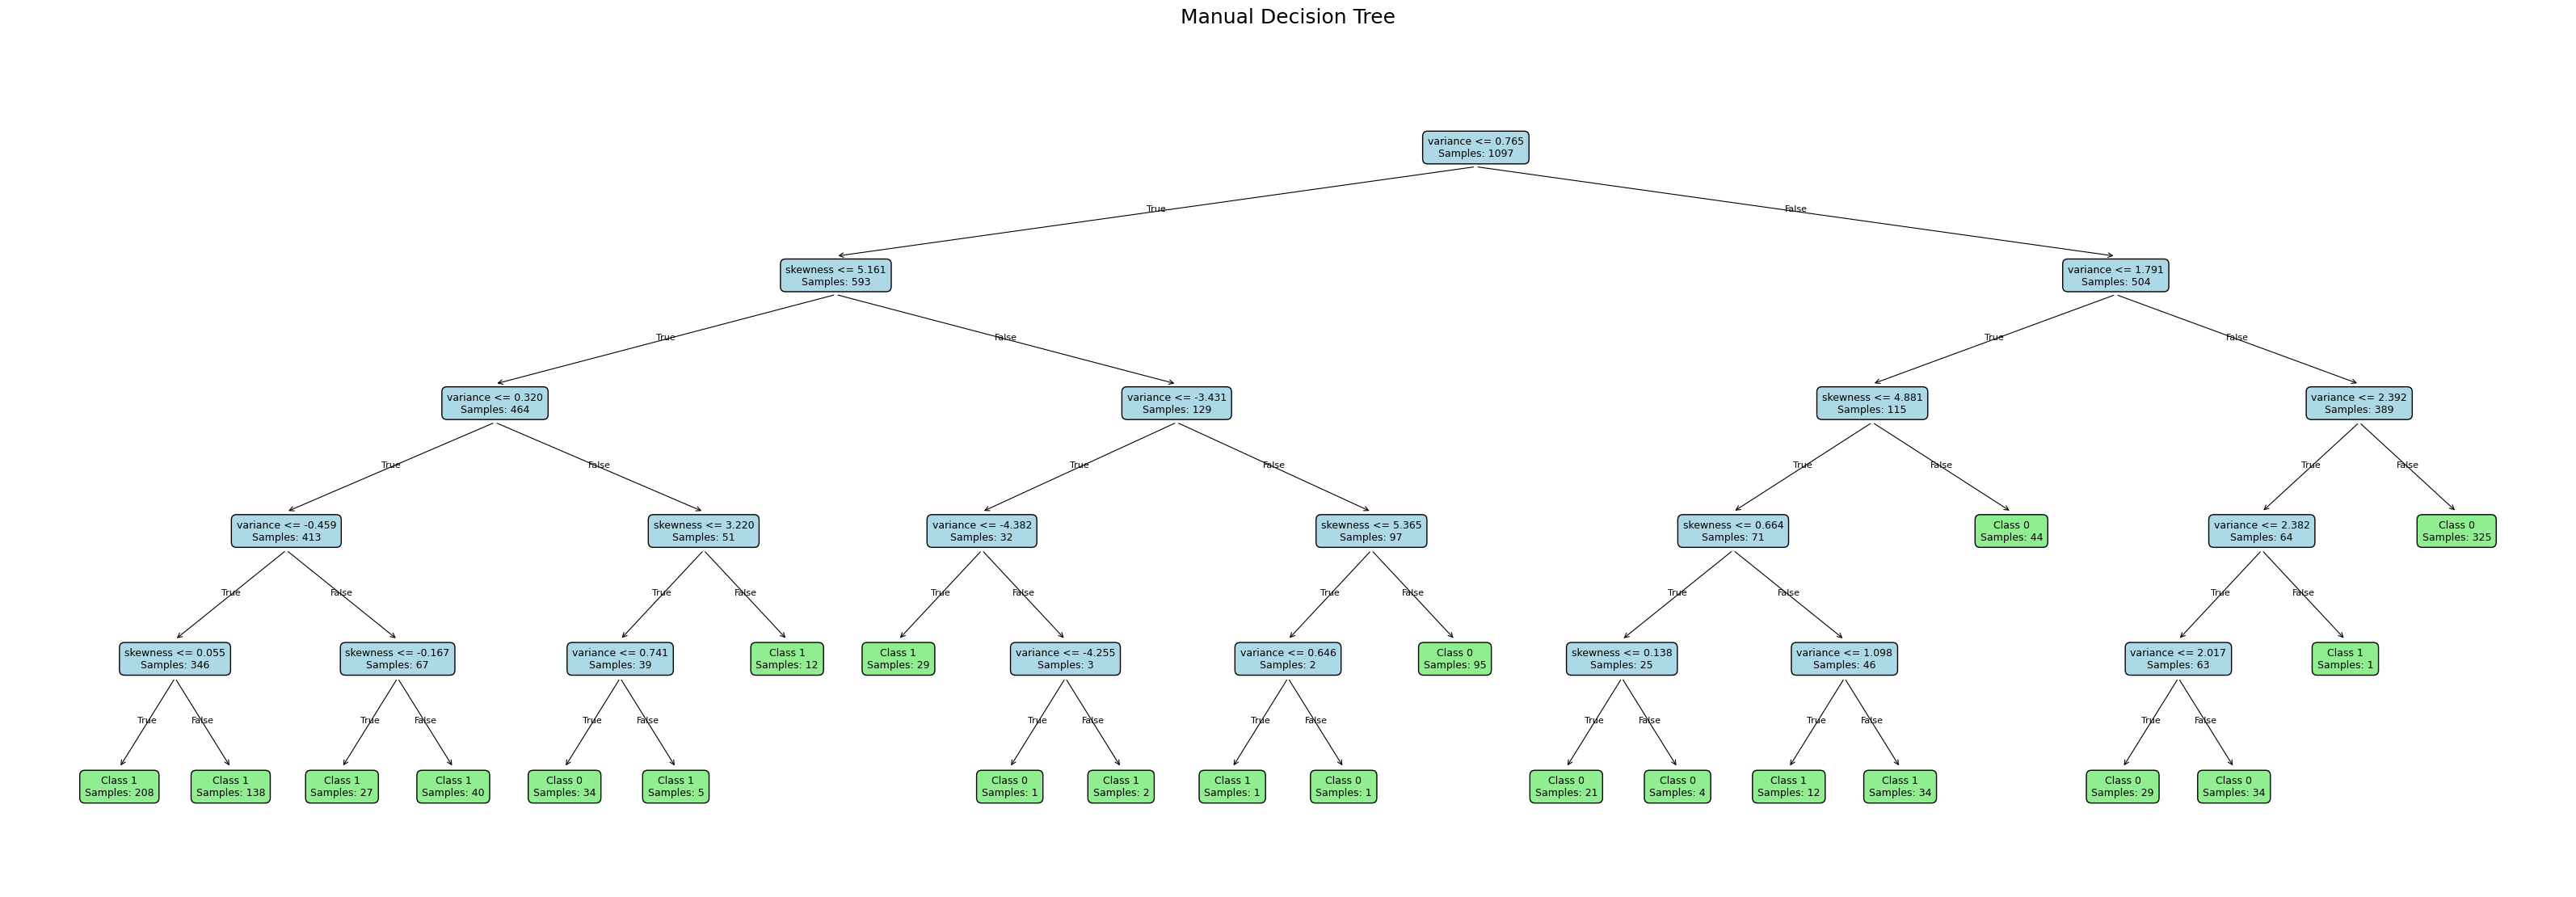

In [32]:
def max_depth_of_tree(node):
    if "feature" not in node:
        return node["depth"]

    return max(
        max_depth_of_tree(node["left"]),
        max_depth_of_tree(node["right"])
    )


def count_leaves(node):
    if "feature" not in node:
        return 1

    return count_leaves(node["left"]) + count_leaves(node["right"])


def plot_manual_tree(node, feature_names):
    positions = {}
    leaf_counter = [0]

    def assign_positions(current):
        if "feature" not in current:
            x_position = leaf_counter[0]
            leaf_counter[0] += 1
        else:
            left_x = assign_positions(current["left"])
            right_x = assign_positions(current["right"])
            x_position = (left_x + right_x) / 2

        positions[id(current)] = (x_position, -current["depth"])
        return x_position

    assign_positions(node)

    leaves = count_leaves(node)
    depth = max_depth_of_tree(node)

    # Increase figure size according to tree width and depth
    fig_width = max(16, leaves * 1.5)
    fig_height = max(8, (depth + 1) * 2.0)

    fig, ax = plt.subplots(figsize=(fig_width, fig_height))

    def draw_nodes(current):
        x, y_position = positions[id(current)]

        if "feature" in current:
            feature = feature_names[current["feature"]]
            threshold = current["threshold"]

            label = (
                f"{feature} <= {threshold:.3f}\n"
                f"Samples: {current['samples']}"
            )
            box_color = "lightblue"
        else:
            label = (
                f"Class {current['prediction']}\n"
                f"Samples: {current['samples']}"
            )
            box_color = "lightgreen"

        ax.text(
            x, y_position, label,
            ha="center",
            va="center",
            fontsize=9,
            bbox=dict(
                boxstyle="round,pad=0.5",
                facecolor=box_color,
                edgecolor="black"
            )
        )

        if "feature" in current:
            for child, edge_label in [
                (current["left"], "True"),
                (current["right"], "False")
            ]:
                child_x, child_y = positions[id(child)]

                ax.annotate(
                    "",
                    xy=(child_x, child_y + 0.15),
                    xytext=(x, y_position - 0.15),
                    arrowprops=dict(
                        arrowstyle="->",
                        color="black",
                        lw=0.8
                    )
                )

                ax.text(
                    (x + child_x) / 2,
                    (y_position + child_y) / 2,
                    edge_label,
                    ha="center",
                    fontsize=8
                )

                draw_nodes(child)

    draw_nodes(node)

    ax.set_title("Manual Decision Tree", fontsize=18, pad=20)
    ax.set_xlim(-1, leaves)
    ax.set_ylim(-depth - 0.8, 0.8)
    ax.axis("off")

    # Avoid tight_layout warning on very wide trees
    fig.subplots_adjust(
        left=0.02, right=0.98,
        top=0.92, bottom=0.05
    )

    plt.show()


plot_manual_tree(manual_tree, feature_names_2d)


###**Plot the Manual Decision Boundary**

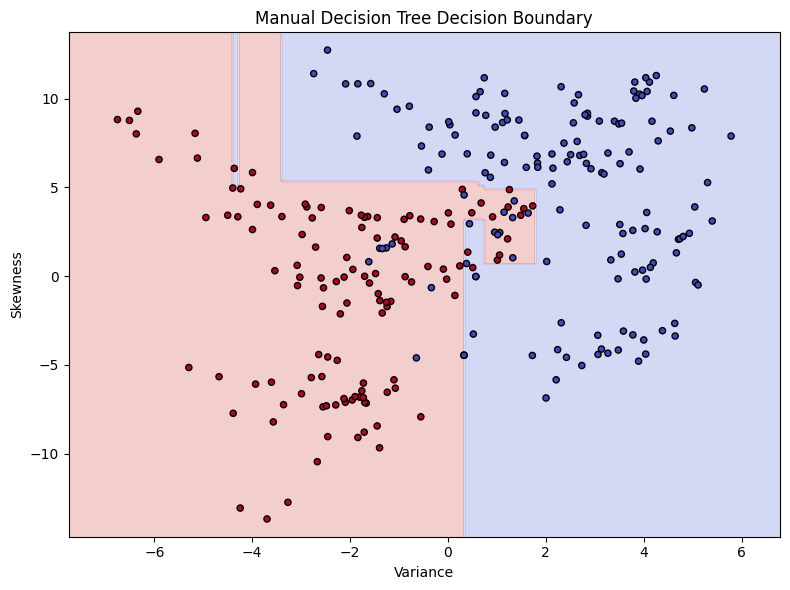

In [33]:
def plot_boundary(model, X_plot, y_plot, title, model_type="manual"):
    x_min, x_max = X_plot[:, 0].min() - 1, X_plot[:, 0].max() + 1
    y_min, y_max = X_plot[:, 1].min() - 1, X_plot[:, 1].max() + 1

    xx, yy = np.meshgrid(
        np.linspace(x_min, x_max, 250),
        np.linspace(y_min, y_max, 250)
    )

    grid = np.c_[xx.ravel(), yy.ravel()]

    if model_type == "manual":
        Z = predict_tree(model, grid)
    else:
        Z = model.predict(grid)

    Z = Z.reshape(xx.shape)

    plt.figure(figsize=(8, 6))
    plt.contourf(xx, yy, Z, alpha=0.25, cmap="coolwarm")
    plt.scatter(
        X_plot[:, 0], X_plot[:, 1],
        c=y_plot, cmap="coolwarm",
        edgecolors="black", s=20
    )

    plt.xlabel("Variance")
    plt.ylabel("Skewness")
    plt.title(title)
    plt.tight_layout()
    plt.show()


plot_boundary(
    manual_tree,
    X_test_2d,
    y_test,
    "Manual Decision Tree Decision Boundary"
)


###**Train and Visualize the Scikit-learn Decision Tree**

Scikit-learn Decision Tree
Test accuracy: 0.9309090909090909

Confusion matrix:
[[137  16]
 [  3 119]]


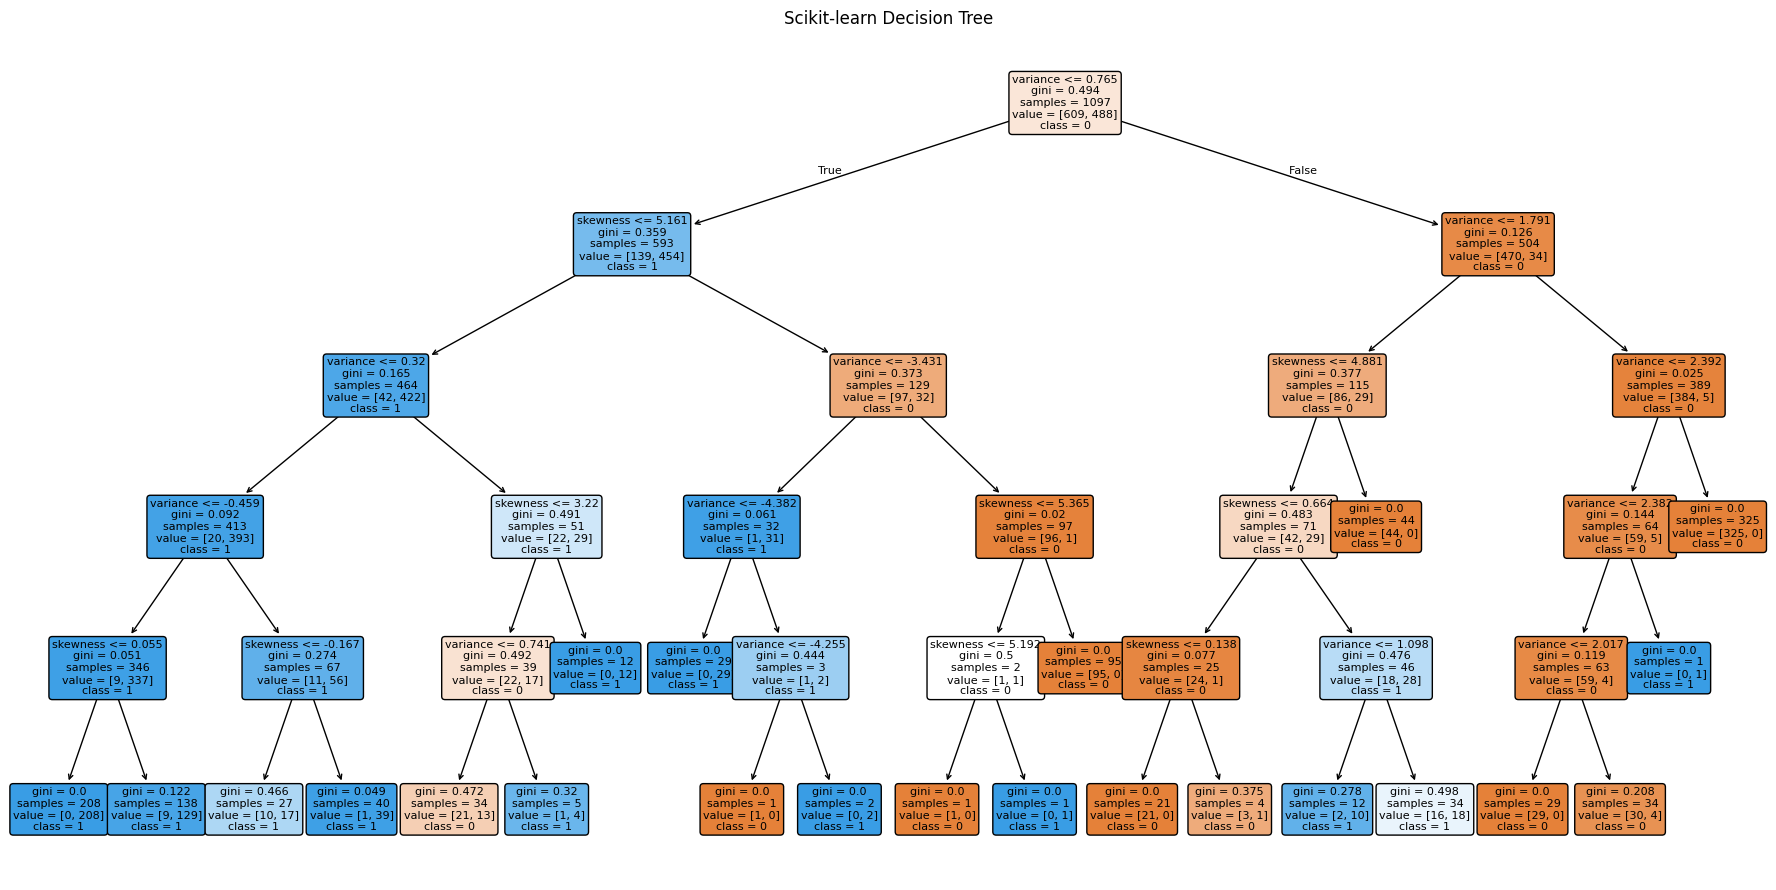

In [36]:
sklearn_tree = DecisionTreeClassifier(
    criterion="gini",
    max_depth=5,
    random_state=42
)

sklearn_tree.fit(X_train_2d, y_train)

sklearn_tree_predictions = sklearn_tree.predict(X_test_2d)

print("Scikit-learn Decision Tree")
print("Test accuracy:", accuracy_score(y_test, sklearn_tree_predictions))
print("\nConfusion matrix:")
print(confusion_matrix(y_test, sklearn_tree_predictions))

plt.figure(figsize=(18, 9))

plot_tree(
    sklearn_tree,
    feature_names=feature_names_2d,
    class_names=["0", "1"],
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Scikit-learn Decision Tree")
plt.tight_layout()
plt.show()




###**Plot the Scikit-learn Decision Boundary**

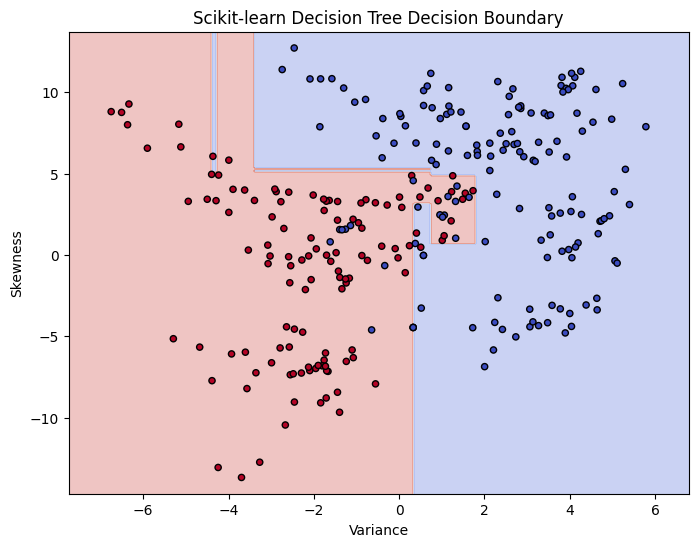

In [37]:
plot_decision_boundary(
    sklearn_tree.predict,
    X_test,
    y_test,
    "Scikit-learn Decision Tree Decision Boundary"
)

###**Compare Gini, Entropy, and Maximum Depth**

In [16]:
results = []

for criterion in ["gini", "entropy"]:
    for depth in [2, 4, 6, None]:

        model = DecisionTreeClassifier(
            criterion=criterion,
            max_depth=depth,
            random_state=42
        )

        model.fit(X_train, y_train)
        predictions = model.predict(X_test)

        results.append({
            "Criterion": criterion,
            "Max Depth": str(depth),
            "Accuracy": accuracy_score(y_test, predictions),
            "Precision": precision_score(
                y_test, predictions, zero_division=0
            ),
            "Recall": recall_score(
                y_test, predictions, zero_division=0
            ),
            "F1-score": f1_score(
                y_test, predictions, zero_division=0
            )
        })

results_df = pd.DataFrame(results)

display(results_df.round(4))

,Criterion,Max Depth,Accuracy,Precision,Recall,F1-score
0,gini,2,0.8764,0.8667,0.8525,0.8595
1,gini,4,0.9345,0.8824,0.9836,0.9302
2,gini,6,0.9309,0.8815,0.9754,0.9261
3,gini,None,0.9200,0.8788,0.9508,0.9134
4,entropy,2,0.8764,0.8667,0.8525,0.8595
5,entropy,4,0.9091,0.8760,0.9262,0.9004
6,entropy,6,0.9382,0.9008,0.9672,0.9328
7,entropy,None,0.9345,0.9062,0.9508,0.9280


###**Compare Manual and Scikit-learn Predictions**

In [17]:
comparison = pd.DataFrame({
    "Actual Class": y_test,
    "Manual Tree Prediction": y_pred_manual,
    "Scikit-learn Prediction": y_pred_sklearn
})

comparison["Predictions Match"] = (
    comparison["Manual Tree Prediction"]
    == comparison["Scikit-learn Prediction"]
)

display(comparison.head(15))

print(
    "Percentage of matching predictions:",
    round(
        100 * comparison["Predictions Match"].mean(),
        2
    ),
    "%"
)

,Actual Class,Manual Tree Prediction,Scikit-learn Prediction,Predictions Match
0,0,0,0,True
1,1,1,1,True
2,0,0,0,True
3,1,1,1,True
4,1,1,1,True
5,1,1,1,True
6,0,0,0,True
7,0,0,0,True
8,0,0,0,True
9,1,1,1,True


Percentage of matching predictions: 100.0 %


##**Part B - Linear SVM from Scratch**

###**Prepare the data**

In [39]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Use the same two features as Part A
feature_names = ["variance", "skewness"]

X = df[feature_names].to_numpy(dtype=float)
y = df["class"].to_numpy(dtype=int)

# Split the data into training and testing sets
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training samples:", len(X_train))
print("Testing samples:", len(X_test))
print("Features:", feature_names)
print("Classes:", np.unique(y))

Training samples: 1097
Testing samples: 275
Features: ['variance', 'skewness']
Classes: [0 1]


###**Scale the features and map labels**

In [40]:
# Learn scaling values from training data only
scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Convert labels: class 0 -> -1, class 1 -> +1
y_train_svm = np.where(y_train == 0, -1, 1)
y_test_svm = np.where(y_test == 0, -1, 1)

print("First 5 scaled training samples:")
print(X_train_scaled[:5])

print("\nFirst 10 SVM training labels:")
print(y_train_svm[:10])

print("\nTraining feature means (approximately zero):")
print(X_train_scaled.mean(axis=0))

First 5 scaled training samples:
[[ 0.39687699  0.05746643]
 [-0.38173115 -0.22255311]
 [ 1.25707446 -0.2779253 ]
 [-0.10891208 -0.29720014]
 [-1.1841959  -0.41950842]]

First 10 SVM training labels:
[ 1  1 -1  1  1  1 -1  1 -1 -1]

Training feature means (approximately zero):
[-8.72390380e-17 -3.24666861e-16]


###**Implement the Linear SVM from scratch**

In [41]:
def train_manual_svm(
    X: np.ndarray,
    y: np.ndarray,
    C: float = 1.0,
    learning_rate: float = 0.001,
    iterations: int = 5000
) -> tuple:
    """
    Train a linear soft-margin SVM using subgradient descent.
    Labels must be -1 and +1.
    """
    n_samples, n_features = X.shape

    w = np.zeros(n_features, dtype=float)
    b = 0.0

    for _ in range(iterations):
        # Calculate scores and margins
        scores = X @ w + b
        margins = y * scores

        # Samples with margin below 1 contribute to hinge loss
        violating = margins < 1

        # Calculate subgradients
        if np.any(violating):
            grad_w = w - C * np.mean(
                X[violating] * y[violating, None],
                axis=0
            ) * (np.sum(violating) / n_samples)

            grad_b = -C * np.sum(y[violating]) / n_samples
        else:
            grad_w = w.copy()
            grad_b = 0.0

        # Update parameters
        w -= learning_rate * grad_w
        b -= learning_rate * grad_b

    return w, b


def predict_manual_svm(
    X: np.ndarray,
    w: np.ndarray,
    b: float
) -> np.ndarray:
    """Predict labels -1 or +1."""
    scores = X @ w + b
    return np.where(scores >= 0, 1, -1)


print("Manual SVM functions created successfully.")

Manual SVM functions created successfully.


###**Train and evaluate the manual SVM**

In [42]:
# Train the manual SVM
start_time = time.perf_counter()

w_manual, b_manual = train_manual_svm(
    X_train_scaled,
    y_train_svm,
    C=1.0,
    learning_rate=0.001,
    iterations=5000
)

manual_train_time = time.perf_counter() - start_time

# Predict on test data
start_time = time.perf_counter()

y_pred_manual_svm = predict_manual_svm(
    X_test_scaled,
    w_manual,
    b_manual
)

manual_prediction_time = time.perf_counter() - start_time

# Convert predictions back to 0 and 1 for evaluation
y_pred_manual_svm_original = np.where(y_pred_manual_svm == -1, 0, 1)

print("Manual SVM weights:", w_manual)
print("Manual SVM bias:", b_manual)

print("\nManual SVM Performance")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_manual_svm_original), 4))
print("Precision:", round(precision_score(y_test, y_pred_manual_svm_original, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_manual_svm_original, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_manual_svm_original, zero_division=0), 4))
print("Training time:", round(manual_train_time, 4), "seconds")
print("Prediction time:", round(manual_prediction_time, 6), "seconds")

Manual SVM weights: [-0.502542   -0.25609766]
Manual SVM bias: -0.26505742935276694

Manual SVM Performance
----------------------
Accuracy: 0.8655
Precision: 0.9126
Recall: 0.7705
F1-score: 0.8356
Training time: 2.074 seconds
Prediction time: 0.000175 seconds


###**Plot the manual SVM boundary, margins, and violating samples**

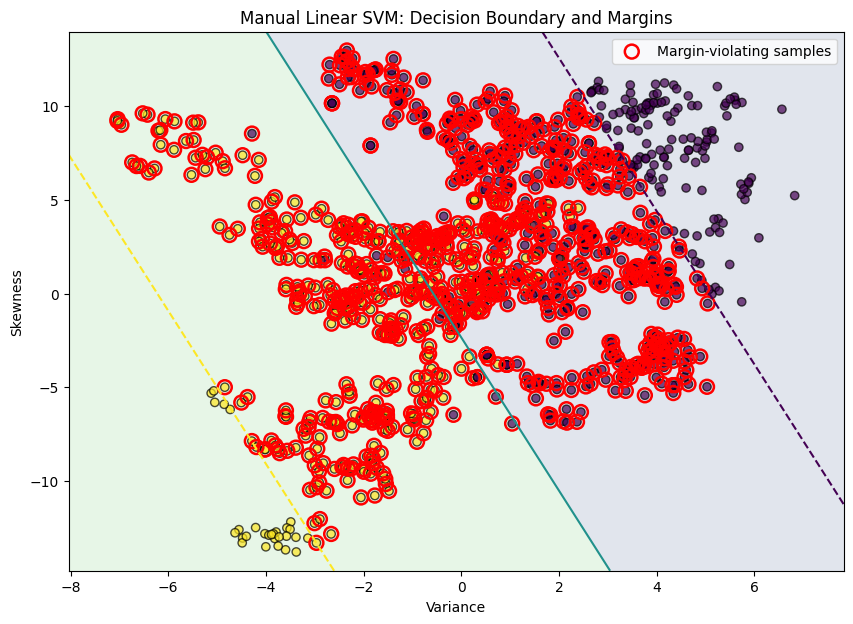

Margin-violating training samples: 932
Total training samples: 1097


In [43]:
# Create a grid in the original feature space
x_min, x_max = X_train[:, 0].min() - 1, X_train[:, 0].max() + 1
y_min, y_max = X_train[:, 1].min() - 1, X_train[:, 1].max() + 1

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_original = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler.transform(grid_original)

# Calculate decision scores
grid_scores = (grid_scaled @ w_manual + b_manual).reshape(xx.shape)

plt.figure(figsize=(10, 7))

# Decision regions
plt.contourf(
    xx, yy, grid_scores,
    levels=[-100, 0, 100],
    alpha=0.15
)

# Decision boundary and margins
plt.contour(
    xx, yy, grid_scores,
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"]
)

# Plot training samples using their original class labels
plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    edgecolors="black",
    alpha=0.7
)

# Identify margin-violating training samples
train_scores = X_train_scaled @ w_manual + b_manual
train_margins = y_train_svm * train_scores
violating_mask = train_margins < 1

plt.scatter(
    X_train[violating_mask, 0],
    X_train[violating_mask, 1],
    s=100,
    facecolors="none",
    edgecolors="red",
    linewidths=1.8,
    label="Margin-violating samples"
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Manual Linear SVM: Decision Boundary and Margins")
plt.legend()
plt.show()

print("Margin-violating training samples:", np.sum(violating_mask))
print("Total training samples:", len(X_train))

###**Train the Scikit-learn Linear SVM**

In [44]:
# Train Scikit-learn linear SVM
sklearn_svm = SVC(kernel="linear", C=1.0)

start_time = time.perf_counter()
sklearn_svm.fit(X_train_scaled, y_train_svm)
sklearn_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()
y_pred_sklearn_svm = sklearn_svm.predict(X_test_scaled)
sklearn_prediction_time = time.perf_counter() - start_time

# Convert predictions to 0 and 1
y_pred_sklearn_original = np.where(y_pred_sklearn_svm == -1, 0, 1)

print("Scikit-learn Linear SVM")
print("----------------------")
print("Accuracy:", round(accuracy_score(y_test, y_pred_sklearn_original), 4))
print("Precision:", round(precision_score(y_test, y_pred_sklearn_original, zero_division=0), 4))
print("Recall:", round(recall_score(y_test, y_pred_sklearn_original, zero_division=0), 4))
print("F1-score:", round(f1_score(y_test, y_pred_sklearn_original, zero_division=0), 4))
print("Training time:", round(sklearn_train_time, 4), "seconds")
print("Prediction time:", round(sklearn_prediction_time, 6), "seconds")

Scikit-learn Linear SVM
----------------------
Accuracy: 0.8764
Precision: 0.8492
Recall: 0.877
F1-score: 0.8629
Training time: 0.0235 seconds
Prediction time: 0.003502 seconds


###**Plot the Scikit-learn SVM boundary**

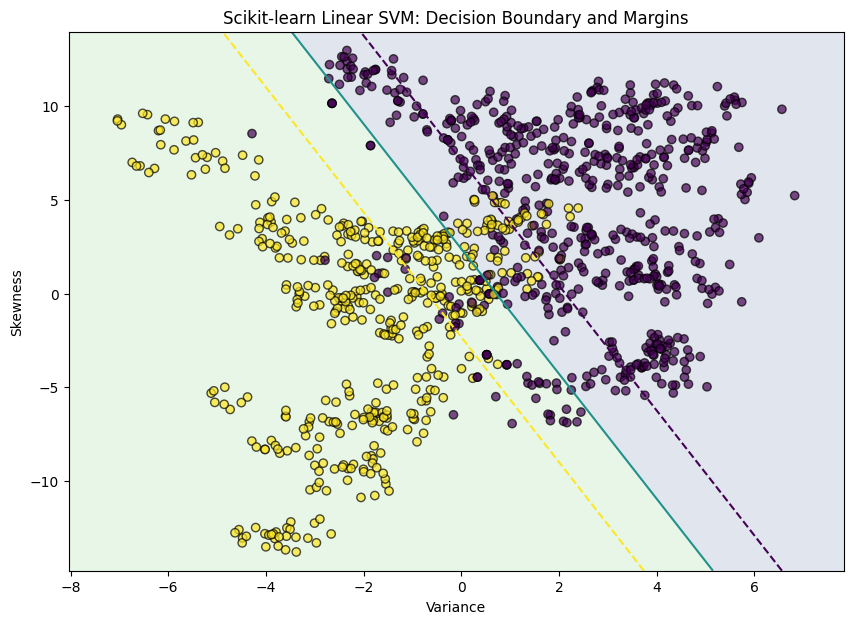

In [45]:
sklearn_grid_scores = sklearn_svm.decision_function(
    grid_scaled
).reshape(xx.shape)

plt.figure(figsize=(10, 7))

plt.contourf(
    xx, yy, sklearn_grid_scores,
    levels=[-100, 0, 100],
    alpha=0.15
)

plt.contour(
    xx, yy, sklearn_grid_scores,
    levels=[-1, 0, 1],
    linestyles=["--", "-", "--"]
)

plt.scatter(
    X_train[:, 0],
    X_train[:, 1],
    c=y_train,
    edgecolors="black",
    alpha=0.7
)

plt.xlabel("Variance")
plt.ylabel("Skewness")
plt.title("Scikit-learn Linear SVM: Decision Boundary and Margins")
plt.show()

###**Compare the manual and Scikit-learn models**

In [46]:
svm_comparison = pd.DataFrame([
    {
        "Model": "Manual Linear SVM",
        "Accuracy": accuracy_score(y_test, y_pred_manual_svm_original),
        "Precision": precision_score(y_test, y_pred_manual_svm_original, zero_division=0),
        "Recall": recall_score(y_test, y_pred_manual_svm_original, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_manual_svm_original, zero_division=0),
        "Training Time (s)": manual_train_time,
        "Prediction Time (s)": manual_prediction_time
    },
    {
        "Model": "Scikit-learn Linear SVM",
        "Accuracy": accuracy_score(y_test, y_pred_sklearn_original),
        "Precision": precision_score(y_test, y_pred_sklearn_original, zero_division=0),
        "Recall": recall_score(y_test, y_pred_sklearn_original, zero_division=0),
        "F1-score": f1_score(y_test, y_pred_sklearn_original, zero_division=0),
        "Training Time (s)": sklearn_train_time,
        "Prediction Time (s)": sklearn_prediction_time
    }
])

display(svm_comparison.round(4))

print(
    "Prediction agreement:",
    round(
        np.mean(y_pred_manual_svm == y_pred_sklearn_svm) * 100,
        2
    ),
    "%"
)

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Linear SVM,0.8655,0.9126,0.7705,0.8356,2.0740,0.0002
1,Scikit-learn Linear SVM,0.8764,0.8492,0.8770,0.8629,0.0235,0.0035


Prediction agreement: 91.64 %


###**The effect of regularization C**

In [47]:
C_results = []

for C_value in [0.01, 0.1, 1.0, 10.0, 100.0]:
    w, b = train_manual_svm(
        X_train_scaled,
        y_train_svm,
        C=C_value,
        learning_rate=0.001,
        iterations=5000
    )

    predictions = predict_manual_svm(
        X_test_scaled, w, b
    )

    predictions_original = np.where(predictions == -1, 0, 1)

    C_results.append({
        "C": C_value,
        "Accuracy": accuracy_score(y_test, predictions_original),
        "Precision": precision_score(y_test, predictions_original, zero_division=0),
        "Recall": recall_score(y_test, predictions_original, zero_division=0),
        "F1-score": f1_score(y_test, predictions_original, zero_division=0)
    })

C_results_df = pd.DataFrame(C_results)
display(C_results_df.round(4))

,C,Accuracy,Precision,Recall,F1-score
0,0.01,0.8582,0.9770,0.6967,0.8134
1,0.10,0.8582,0.9770,0.6967,0.8134
2,1.00,0.8655,0.9126,0.7705,0.8356
3,10.00,0.8873,0.8957,0.8443,0.8692
4,100.00,0.8836,0.8750,0.8607,0.8678


###**The effect of learning rate**

In [48]:
learning_rate_results = []

for lr in [0.0001, 0.001, 0.005, 0.01]:
    w, b = train_manual_svm(
        X_train_scaled,
        y_train_svm,
        C=1.0,
        learning_rate=lr,
        iterations=5000
    )

    predictions = predict_manual_svm(
        X_test_scaled, w, b
    )

    predictions_original = np.where(predictions == -1, 0, 1)

    learning_rate_results.append({
        "Learning Rate": lr,
        "Accuracy": accuracy_score(y_test, predictions_original),
        "F1-score": f1_score(y_test, predictions_original, zero_division=0)
    })

learning_rate_df = pd.DataFrame(learning_rate_results)
display(learning_rate_df.round(4))

,Learning Rate,Accuracy,F1-score
0,0.0001,0.8909,0.8750
1,0.0010,0.8655,0.8356
2,0.0050,0.8655,0.8341
3,0.0100,0.8655,0.8341


###**The effect of iterations**

In [49]:
iteration_results = []

for number_of_iterations in [100, 500, 1000, 5000, 10000]:
    w, b = train_manual_svm(
        X_train_scaled,
        y_train_svm,
        C=1.0,
        learning_rate=0.001,
        iterations=number_of_iterations
    )

    predictions = predict_manual_svm(
        X_test_scaled, w, b
    )

    predictions_original = np.where(predictions == -1, 0, 1)

    iteration_results.append({
        "Iterations": number_of_iterations,
        "Accuracy": accuracy_score(y_test, predictions_original),
        "F1-score": f1_score(y_test, predictions_original, zero_division=0)
    })

iteration_df = pd.DataFrame(iteration_results)
display(iteration_df.round(4))

,Iterations,Accuracy,F1-score
0,100,0.8836,0.8678
1,500,0.8909,0.8750
2,1000,0.8873,0.8692
3,5000,0.8655,0.8356
4,10000,0.8655,0.8341


##**Part C - Kernel SVM and Nonlinear Boundaries**

###**Generate a nonlinear dataset**

Dataset shape: (500, 2)
Number of samples: 500
Classes: [0 1]


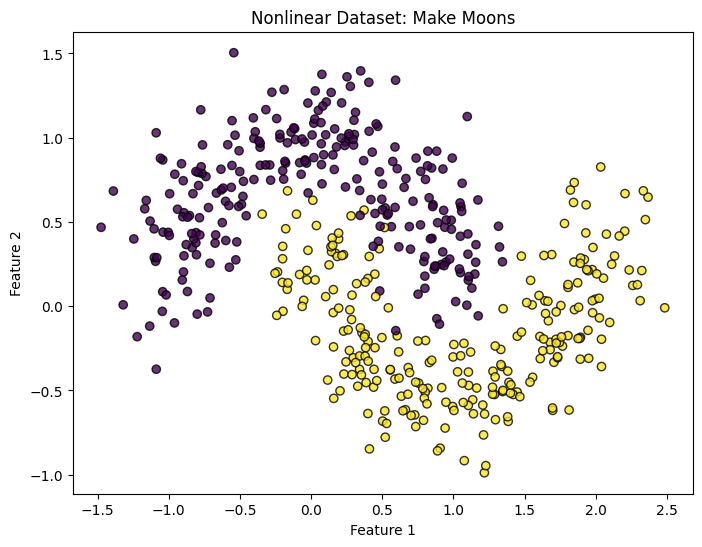

In [50]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score

# Generate two interleaving moon-shaped classes
X_moons, y_moons = make_moons(
    n_samples=500,
    noise=0.20,
    random_state=42
)

print("Dataset shape:", X_moons.shape)
print("Number of samples:", len(y_moons))
print("Classes:", np.unique(y_moons))

# Visualize the dataset
plt.figure(figsize=(8, 6))

plt.scatter(
    X_moons[:, 0],
    X_moons[:, 1],
    c=y_moons,
    edgecolors="black",
    alpha=0.8
)

plt.xlabel("Feature 1")
plt.ylabel("Feature 2")
plt.title("Nonlinear Dataset: Make Moons")
plt.show()

###**Split and scale the data**

In [51]:
X_train_moons, X_test_moons, y_train_moons, y_test_moons = train_test_split(
    X_moons,
    y_moons,
    test_size=0.2,
    random_state=42,
    stratify=y_moons
)

scaler_moons = StandardScaler()

X_train_moons_scaled = scaler_moons.fit_transform(X_train_moons)
X_test_moons_scaled = scaler_moons.transform(X_test_moons)

print("Training samples:", len(X_train_moons))
print("Testing samples:", len(X_test_moons))

Training samples: 400
Testing samples: 100


###**Train the three SVM models**

In [52]:
svm_models = {
    "Linear SVM": SVC(kernel="linear", C=1.0),
    "Polynomial SVM": SVC(kernel="poly", degree=3, C=1.0, gamma="scale"),
    "RBF SVM": SVC(kernel="rbf", C=1.0, gamma="scale")
}

for name, model in svm_models.items():
    model.fit(X_train_moons_scaled, y_train_moons)
    print(name, "trained successfully.")

Linear SVM trained successfully.
Polynomial SVM trained successfully.
RBF SVM trained successfully.


###**Plot all three decision boundaries**

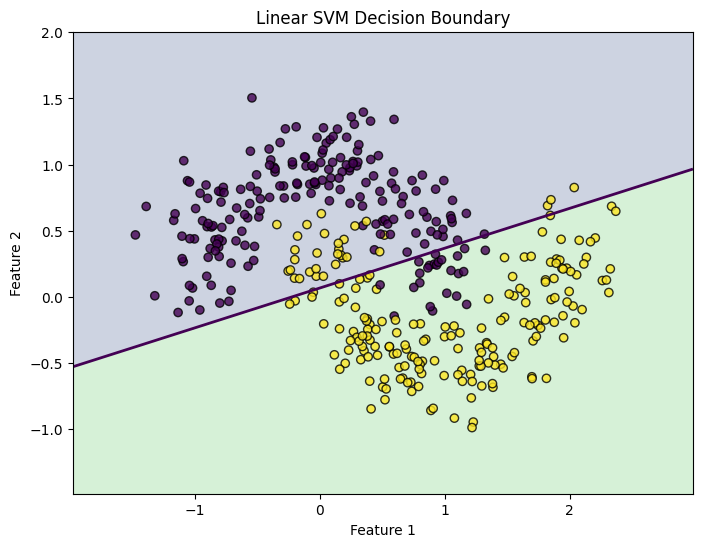

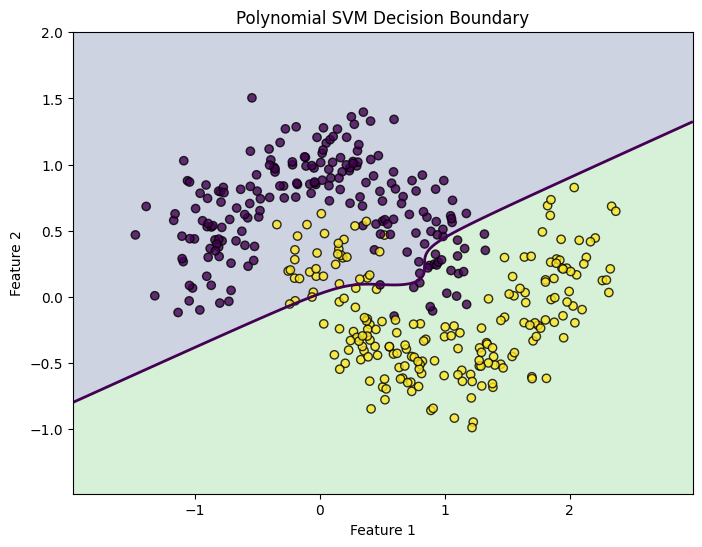

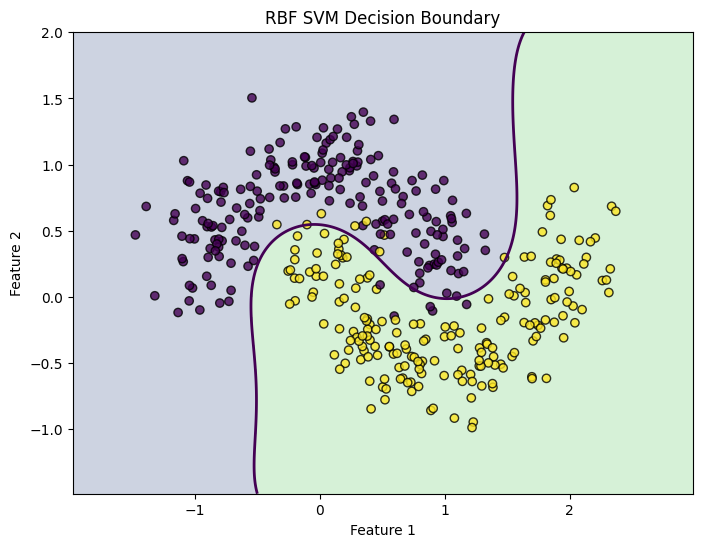

In [53]:
# Create a grid in the original feature space
x_min, x_max = X_moons[:, 0].min() - 0.5, X_moons[:, 0].max() + 0.5
y_min, y_max = X_moons[:, 1].min() - 0.5, X_moons[:, 1].max() + 0.5

xx, yy = np.meshgrid(
    np.linspace(x_min, x_max, 300),
    np.linspace(y_min, y_max, 300)
)

grid_original = np.c_[xx.ravel(), yy.ravel()]
grid_scaled = scaler_moons.transform(grid_original)

for name, model in svm_models.items():

    # Predict the class for each grid point
    predictions = model.predict(grid_scaled).reshape(xx.shape)

    plt.figure(figsize=(8, 6))

    # Display predicted regions
    plt.contourf(
        xx,
        yy,
        predictions,
        alpha=0.25,
        levels=[-0.5, 0.5, 1.5]
    )

    # Draw the decision boundary
    decision_scores = model.decision_function(
        grid_scaled
    ).reshape(xx.shape)

    plt.contour(
        xx,
        yy,
        decision_scores,
        levels=[0],
        linewidths=2
    )

    # Display training samples
    plt.scatter(
        X_train_moons[:, 0],
        X_train_moons[:, 1],
        c=y_train_moons,
        edgecolors="black",
        alpha=0.8
    )

    plt.xlabel("Feature 1")
    plt.ylabel("Feature 2")
    plt.title(name + " Decision Boundary")
    plt.show()

###**Compare model performance**

In [54]:
kernel_results = []

for name, model in svm_models.items():

    y_pred = model.predict(X_test_moons_scaled)

    kernel_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test_moons, y_pred),
        "Precision": precision_score(y_test_moons, y_pred, zero_division=0),
        "Recall": recall_score(y_test_moons, y_pred, zero_division=0),
        "F1-score": f1_score(y_test_moons, y_pred, zero_division=0)
    })

kernel_results_df = pd.DataFrame(kernel_results)

display(kernel_results_df.round(4))

,Model,Accuracy,Precision,Recall,F1-score
0,Linear SVM,0.86,0.8462,0.88,0.8627
1,Polynomial SVM,0.85,0.8571,0.84,0.8485
2,RBF SVM,0.99,1.0000,0.98,0.9899


###**Kernel SVM and Nonlinear Decision Boundaries**
The make_moons dataset contains two interleaving classes with a nonlinear structure. A Linear SVM creates a straight decision boundary, which may not separate the two classes effectively.

The Polynomial kernel can model nonlinear relationships by considering polynomial combinations of the input features. The RBF (Radial Basis Function) kernel can create more flexible decision boundaries by measuring similarity between data points.


For this dataset, nonlinear kernels may perform better than the linear kernel because they can represent curved class boundaries. However, their performance depends on parameters such as C, gamma, and the polynomial degree. The test-set metrics and decision-boundary plots help compare their performance.

##**Part D - Final Comparison**

###**Prepare the original dataset using all four features**

In [55]:
import numpy as np
import pandas as pd
import time

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.tree import DecisionTreeClassifier
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

# Use all four original Banknote features
features_D = ["variance", "skewness", "curtosis", "entropy"]

X_D = df[features_D].to_numpy(dtype=float)
y_D = df["class"].to_numpy(dtype=int)

# Use the same split for every model
X_D_train, X_D_test, y_D_train, y_D_test = train_test_split(
    X_D,
    y_D,
    test_size=0.2,
    random_state=42,
    stratify=y_D
)

print("Training samples:", len(X_D_train))
print("Testing samples:", len(X_D_test))
print("Number of features:", X_D_train.shape[1])
print("Features:", features_D)

Training samples: 1097
Testing samples: 275
Number of features: 4
Features: ['variance', 'skewness', 'curtosis', 'entropy']


###**Train the manual Decision Tree**

In [58]:

# Predict using the manual decision tree
manual_tree_D_pred = np.asarray(
    predict_tree(manual_tree_D, X_D_test),
    dtype=int
)

print("Manual Decision Tree Accuracy:",
      accuracy_score(y_D_test, manual_tree_D_pred))


Manual Decision Tree Accuracy: 0.9709090909090909


###**Train the Scikit-learn Decision Tree**

In [60]:
sklearn_tree_D = DecisionTreeClassifier(
    criterion="gini",
    max_depth=4,
    random_state=42
)

start_time = time.perf_counter()

sklearn_tree_D.fit(X_D_train, y_D_train)

sklearn_tree_D_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

sklearn_tree_D_pred = sklearn_tree_D.predict(X_D_test)

sklearn_tree_D_prediction_time = time.perf_counter() - start_time

print("Scikit-learn Decision Tree trained successfully.")
print("Training time:", round(sklearn_tree_D_train_time, 4), "seconds")
print("Prediction time:", round(sklearn_tree_D_prediction_time, 6), "seconds")

Scikit-learn Decision Tree trained successfully.
Training time: 0.0107 seconds
Prediction time: 0.000794 seconds


###**Scale the data for SVM models**

In [61]:
scaler_D = StandardScaler()

X_D_train_scaled = scaler_D.fit_transform(X_D_train)
X_D_test_scaled = scaler_D.transform(X_D_test)

# Convert labels from 0/1 to -1/+1 for the manual SVM
y_D_train_svm = np.where(y_D_train == 0, -1, 1)
y_D_test_svm = np.where(y_D_test == 0, -1, 1)

print("Training data shape:", X_D_train_scaled.shape)
print("Testing data shape:", X_D_test_scaled.shape)
print("SVM labels:", np.unique(y_D_train_svm))

Training data shape: (1097, 4)
Testing data shape: (275, 4)
SVM labels: [-1  1]


###**Train the manual Linear SVM**

In [62]:
start_time = time.perf_counter()

w_manual_D, b_manual_D = train_manual_svm(
    X_D_train_scaled,
    y_D_train_svm,
    C=1.0,
    learning_rate=0.001,
    iterations=5000
)

manual_svm_D_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

manual_svm_D_pred = predict_manual_svm(
    X_D_test_scaled,
    w_manual_D,
    b_manual_D
)

manual_svm_D_prediction_time = time.perf_counter() - start_time

# Convert predictions back to 0/1
manual_svm_D_pred = np.where(manual_svm_D_pred == -1, 0, 1)

print("Manual Linear SVM trained successfully.")
print("Weights:", w_manual_D)
print("Bias:", b_manual_D)
print("Training time:", round(manual_svm_D_train_time, 4), "seconds")
print("Prediction time:", round(manual_svm_D_prediction_time, 6), "seconds")

Manual Linear SVM trained successfully.
Weights: [-0.50954657 -0.2726775  -0.03076284 -0.03108713]
Bias: -0.25809662716500725
Training time: 1.3877 seconds
Prediction time: 0.000283 seconds


###**Train the Scikit-learn Linear SVM**

In [63]:
sklearn_linear_D = SVC(
    kernel="linear",
    C=1.0
)

start_time = time.perf_counter()

sklearn_linear_D.fit(
    X_D_train_scaled,
    y_D_train_svm
)

sklearn_linear_D_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

sklearn_linear_D_pred = sklearn_linear_D.predict(X_D_test_scaled)

sklearn_linear_D_prediction_time = time.perf_counter() - start_time

# Convert predictions back to 0/1
sklearn_linear_D_pred = np.where(
    sklearn_linear_D_pred == -1, 0, 1
)

print("Scikit-learn Linear SVM trained successfully.")
print("Training time:", round(sklearn_linear_D_train_time, 4), "seconds")
print("Prediction time:", round(sklearn_linear_D_prediction_time, 6), "seconds")

Scikit-learn Linear SVM trained successfully.
Training time: 0.0146 seconds
Prediction time: 0.00159 seconds


###**Train the RBF SVM**

In [64]:
sklearn_rbf_D = SVC(
    kernel="rbf",
    C=1.0,
    gamma="scale"
)

start_time = time.perf_counter()

sklearn_rbf_D.fit(
    X_D_train_scaled,
    y_D_train_svm
)

rbf_D_train_time = time.perf_counter() - start_time

start_time = time.perf_counter()

rbf_D_pred = sklearn_rbf_D.predict(X_D_test_scaled)

rbf_D_prediction_time = time.perf_counter() - start_time

# Convert predictions back to 0/1
rbf_D_pred = np.where(rbf_D_pred == -1, 0, 1)

print("RBF SVM trained successfully.")
print("Training time:", round(rbf_D_train_time, 4), "seconds")
print("Prediction time:", round(rbf_D_prediction_time, 6), "seconds")

RBF SVM trained successfully.
Training time: 0.0117 seconds
Prediction time: 0.003202 seconds


###**Compare all five models**

In [68]:
# Create predictions for the Scikit-learn Linear SVM
import time
from sklearn.svm import SVC

sklearn_linear_svm_D = SVC(kernel="linear", C=1.0)

start = time.perf_counter()
sklearn_linear_svm_D.fit(X_D_train_scaled, y_D_train_svm)
sklearn_linear_svm_D_train_time = time.perf_counter() - start

start = time.perf_counter()
sklearn_linear_svm_D_pred = sklearn_linear_svm_D.predict(X_D_test_scaled)
sklearn_linear_svm_D_prediction_time = time.perf_counter() - start

# Convert predictions from -1/+1 back to 0/1
sklearn_linear_svm_D_pred = np.where(
    sklearn_linear_svm_D_pred == -1, 0, 1
)

print("Scikit-learn Linear SVM Accuracy:",
      accuracy_score(y_D_test, sklearn_linear_svm_D_pred))

Scikit-learn Linear SVM Accuracy: 0.9745454545454545


In [69]:
models_D = [
    (
        "Manual Decision Tree",
        manual_tree_D_pred,
        manual_tree_D_train_time,
        manual_tree_D_prediction_time
    ),
    (
        "Scikit-learn Decision Tree",
        sklearn_tree_D_pred,
        sklearn_tree_D_train_time,
        sklearn_tree_D_prediction_time
    ),
    (
        "Manual Linear SVM",
        manual_svm_D_pred,
        manual_svm_D_train_time,
        manual_svm_D_prediction_time
    ),
    (
        "Scikit-learn Linear SVM",
        sklearn_linear_D_pred,
        sklearn_linear_D_train_time,
        sklearn_linear_D_prediction_time
    ),
    (
        "Scikit-learn RBF SVM",
        rbf_D_pred,
        rbf_D_train_time,
        rbf_D_prediction_time
    )
]

comparison_rows_D = []

for name, predictions, train_time, prediction_time in models_D:
    comparison_rows_D.append({
        "Model": name,
        "Accuracy": accuracy_score(y_D_test, predictions),
        "Precision": precision_score(
            y_D_test, predictions, zero_division=0
        ),
        "Recall": recall_score(
            y_D_test, predictions, zero_division=0
        ),
        "F1-score": f1_score(
            y_D_test, predictions, zero_division=0
        ),
        "Training Time (s)": train_time,
        "Prediction Time (s)": prediction_time
    })

comparison_D = pd.DataFrame(comparison_rows_D)

display(comparison_D.round(4))

,Model,Accuracy,Precision,Recall,F1-score,Training Time (s),Prediction Time (s)
0,Manual Decision Tree,0.9709,0.9385,1.0000,0.9683,3.6956,0.0011
1,Scikit-learn Decision Tree,0.9709,0.9385,1.0000,0.9683,0.0107,0.0008
2,Manual Linear SVM,0.8800,0.9238,0.7951,0.8546,1.3877,0.0003
3,Scikit-learn Linear SVM,0.9745,0.9457,1.0000,0.9721,0.0146,0.0016
4,Scikit-learn RBF SVM,1.0000,1.0000,1.0000,1.0000,0.0117,0.0032


###**Compare the models visually**

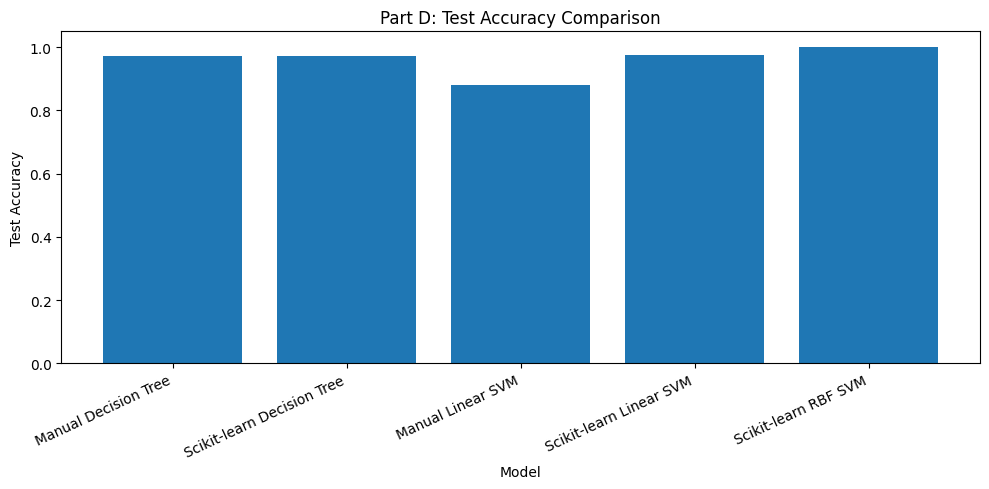

In [70]:
plt.figure(figsize=(10, 5))

plt.bar(
    comparison_D["Model"],
    comparison_D["Accuracy"]
)

plt.ylabel("Test Accuracy")
plt.xlabel("Model")
plt.title("Part D: Test Accuracy Comparison")
plt.ylim(0, 1.05)
plt.xticks(rotation=25, ha="right")
plt.tight_layout()
plt.show()

###**Final Comparison and Observations**
The five models were trained and evaluated using the original Banknote Authentication dataset with all four features. A consistent 80:20 train-test split was used with random_state=42 and stratification to maintain class proportions.

**Decision Tree comparison**: The manual Decision Tree was implemented using NumPy, while the Scikit-learn Decision Tree used the library's optimized implementation. Decision Trees are relatively easy to interpret because their predictions are based on feature-threshold rules. However, deeper trees can overfit the training data.

**Linear SVM comparison**: The manual and Scikit-learn Linear SVM models use a linear decision function. Features were standardized using training-set statistics because SVM models are sensitive to feature scales. The manual model uses subgradient descent, while Scikit-learn uses its own optimization procedure. Differences in their performance may result from the optimization methods and convergence.

**RBF SVM**: The RBF kernel can model nonlinear relationships between features, unlike a linear SVM. This flexibility may improve classification when the relationship between the features and classes is nonlinear. However, its performance depends on parameters such as C and gamma.

**Overfitting and model complexity**: Decision Trees can overfit when they grow too deep. Linear SVMs have a linear decision boundary, while RBF SVMs can produce more complex nonlinear boundaries. Model performance should therefore be assessed using test-set metrics rather than training accuracy alone.

**Conclusion**: The comparison table shows how the models perform on the same test data. The model with the highest test accuracy is not necessarily best for every purpose; precision, recall, F1-score, execution time, and interpretability should also be considered. The final choice should be based on the actual measured results.